#### Repository link
https://github.com/GeorgeM07/Statistics_Sept2026.git

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

#First we open the data file and see some insights about it (preview)
df= pd.read_csv('Pokemon.csv')
df

,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,1,False
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,False
3,3,VenusaurMega Venusaur,Grass,Poison,625,80,100,123,122,120,80,1,False
4,4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,719,Diancie,Rock,Fairy,600,50,100,150,100,150,50,6,True
796,719,DiancieMega Diancie,Rock,Fairy,700,50,160,110,160,110,110,6,True
797,720,HoopaHoopa Confined,Psychic,Ghost,600,80,110,60,150,130,70,6,True
798,720,HoopaHoopa Unbound,Psychic,Dark,680,80,160,60,170,130,80,6,True


We can see here the name of the columns (variables) and if they are numerical or categorical
we can also see that the data set has 800 rowns and 13 columns (dimensions)
The 'Total' row is the sum of all the basic stats for the specific Pokemon (From HP to Speed)


In [2]:
df.describe()

,#,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation
count,800.000000,800.00000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000,800.00000
mean,362.813750,435.10250,69.258750,79.001250,73.842500,72.820000,71.902500,68.277500,3.32375
std,208.343798,119.96304,25.534669,32.457366,31.183501,32.722294,27.828916,29.060474,1.66129
min,1.000000,180.00000,1.000000,5.000000,5.000000,10.000000,20.000000,5.000000,1.00000
25%,184.750000,330.00000,50.000000,55.000000,50.000000,49.750000,50.000000,45.000000,2.00000
50%,364.500000,450.00000,65.000000,75.000000,70.000000,65.000000,70.000000,65.000000,3.00000
75%,539.250000,515.00000,80.000000,100.000000,90.000000,95.000000,90.000000,90.000000,5.00000
max,721.000000,780.00000,255.000000,190.000000,230.000000,194.000000,230.000000,180.000000,6.00000


In [3]:

#In Generation we can observe that the data was gethered from the 1st to the 6th Generation
#Just out of curiosity I requested the info of the 3 original Pokemon starters and their evolutions

df.head(13)

,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,318,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,405,60,62,63,80,80,60,1,False
2,3,Venusaur,Grass,Poison,525,80,82,83,100,100,80,1,False
3,3,VenusaurMega Venusaur,Grass,Poison,625,80,100,123,122,120,80,1,False
4,4,Charmander,Fire,NaN,309,39,52,43,60,50,65,1,False
5,5,Charmeleon,Fire,NaN,405,58,64,58,80,65,80,1,False
6,6,Charizard,Fire,Flying,534,78,84,78,109,85,100,1,False
7,6,CharizardMega Charizard X,Fire,Dragon,634,78,130,111,130,85,100,1,False
8,6,CharizardMega Charizard Y,Fire,Flying,634,78,104,78,159,115,100,1,False
9,7,Squirtle,Water,NaN,314,44,48,65,50,64,43,1,False


In [4]:
#With the following commands we can check if there are any missing values

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   #           800 non-null    int64 
 1   Name        800 non-null    object
 2   Type 1      800 non-null    object
 3   Type 2      414 non-null    object
 4   Total       800 non-null    int64 
 5   HP          800 non-null    int64 
 6   Attack      800 non-null    int64 
 7   Defense     800 non-null    int64 
 8   Sp. Atk     800 non-null    int64 
 9   Sp. Def     800 non-null    int64 
 10  Speed       800 non-null    int64 
 11  Generation  800 non-null    int64 
 12  Legendary   800 non-null    bool  
dtypes: bool(1), int64(9), object(3)
memory usage: 75.9+ KB


In [5]:
df.isnull().sum()

#               0
Name            0
Type 1          0
Type 2        386
Total           0
HP              0
Attack          0
Defense         0
Sp. Atk         0
Sp. Def         0
Speed           0
Generation      0
Legendary       0
dtype: int64

In [6]:
#The data set has no missing values
#The following command generates a summary statistics of the string/object variables

df.describe(include=['object'])

,Name,Type 1,Type 2
count,800,800,414
unique,800,18,18
top,Bulbasaur,Water,Flying
freq,1,112,97


We can see that we have 800 different names for each one of the 800 Pokemon on the list. 
We can also see that the 18 different pokemon types are included as Type 1 or Type 2
Also the more repeated type 1 is water (this means that most of the Pokemon are water type) with 112
And the type 2 is flying, which means that the most repeated second type in pokemons is flying type, with 97

In [7]:
#Just as an exercise, we want to know how many Legendary Pokemon there are on the data list
filtered_df = df[df['Legendary']==True]
display(filtered_df)

,#,Name,Type 1,Type 2,Total,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
156,144,Articuno,Ice,Flying,580,90,85,100,95,125,85,1,True
157,145,Zapdos,Electric,Flying,580,90,90,85,125,90,100,1,True
158,146,Moltres,Fire,Flying,580,90,100,90,125,85,90,1,True
162,150,Mewtwo,Psychic,NaN,680,106,110,90,154,90,130,1,True
163,150,MewtwoMega Mewtwo X,Psychic,Fighting,780,106,190,100,154,100,130,1,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,719,Diancie,Rock,Fairy,600,50,100,150,100,150,50,6,True
796,719,DiancieMega Diancie,Rock,Fairy,700,50,160,110,160,110,110,6,True
797,720,HoopaHoopa Confined,Psychic,Ghost,600,80,110,60,150,130,70,6,True
798,720,HoopaHoopa Unbound,Psychic,Dark,680,80,160,60,170,130,80,6,True


In [8]:
#Above we can see that we have a total of 65 Legendary Pokemons

## Computation of measures of central tendency
Measures of central tendency - mean, median and mode.

I will use the 'Total' variable for calculations.

In [9]:
mean=df['Total'].mean()
print(mean)

435.1025


In [10]:
median=df['Total'].median()
print(median)

450.0


In [11]:
mode=df['Total'].mode()
print(mode)

0    600
Name: Total, dtype: int64


In [12]:
#Mean<median

## Calculation of measures of dispersion

In [13]:
df['Total'].min()

180

In [14]:
df['Total'].max()

780

In [15]:
#Range
df['Total'].max()-df['Total'].min()

600

In [16]:
#Variance
df['Total'].var()

14391.130907384233

In [17]:
#Std deviation
df['Total'].std()

119.963039755519

## IQR

In [18]:
#50th Percentile or median
Q2=df['Total'].quantile(0.5)  
Q2

450.0

In [19]:
#25th percentile
Q1=df['Total'].quantile(0.25)
Q1

330.0

In [20]:
#75th percentile
Q3=df['Total'].quantile(0.75)
Q3

515.0

In [21]:
#Interquantile range
IQR=Q3-Q1
IQR

185.0

### Histogram

<Axes: xlabel='Total', ylabel='Count'>

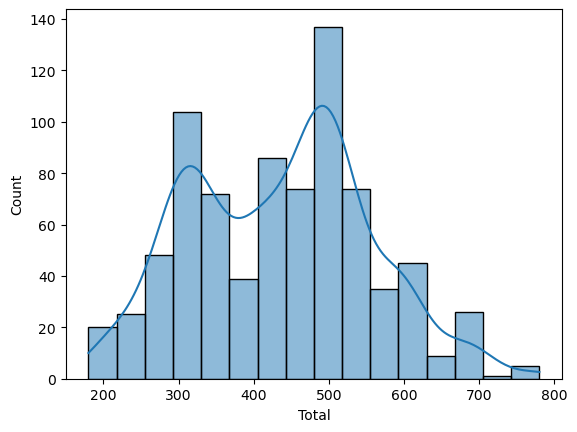

In [22]:
data=df['Total']

sns.histplot(df['Total'],kde=True)

In [23]:
df['Total'].skew()

0.1525299233953993

We can see that the skewness is greater but close 0. We can also see  that the value is between 0 and 0.5 so is slightly skewed.

In [24]:
#Lets try now with the kurtosis
df['Total'].kurt()

-0.5074607103228463

Since the kurtosis is lesser than 3 we can conclude that the Total curve is Platykurtic:It features thin or light tails, meaning extreme outliers are rare, and flatter peak compared to a Normal distribution.

### Outliers

In [25]:
total= df['Total'].dropna()

q1 = total.quantile(0.25)
q3 = total.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = df[(df['Total'] < lower_bound) |
              (df['Total'] > upper_bound)]

print('Lower bound:', lower_bound)
print('Upper bound:', upper_bound)
print('Number of outliers:', len(outliers))


Lower bound: 52.5
Upper bound: 792.5
Number of outliers: 0


In [26]:
LB=Q1-1.5*IQR #Lower bound
print(LB)

52.5


In [27]:
UB=Q3+1.5*IQR #Upper bound
print(UB)

792.5


Acording to this there are no outliers in the distribution.

## Boxplot

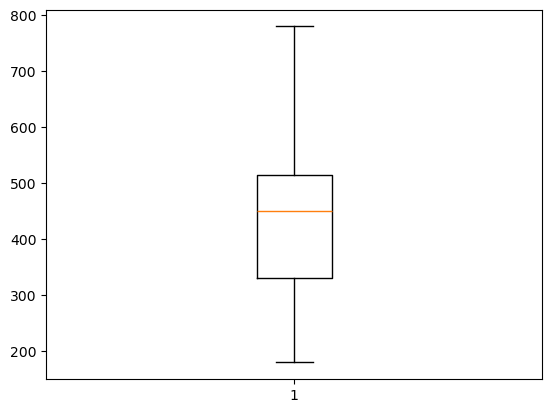

In [28]:
plt.boxplot(df['Total'])
plt.show()

### Binomial distribution

#### **Formula**:
The probability of getting exactly \( k \) successes in \( n \) independent trials is given by the binomial probability formula:

$$
P(X = k) = {n \choose k} \cdot p^k \cdot (1 - p)^{n - k}
$$

Where:
- \( n \) = number of trials
- \( k \) = number of successes
- \( p \) = probability of success on a single trial
- \( (1 - p) \) = probability of failure

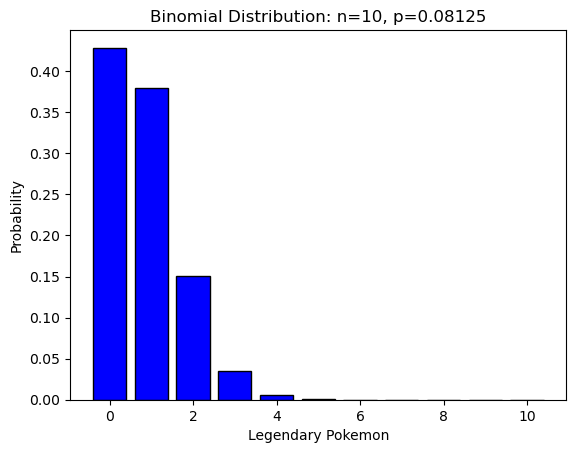

In [29]:
import scipy.stats as stats
from scipy.stats import binom

# Parameters
n = 10  # Number of trials
p = 0.08125  # Probability of success (getting a Legendary Pokemon)
k = np.arange(0, n + 1)  # Number of possible successes (0 to 10)

# Binomial probability mass function (pmf)
binom_pmf = binom.pmf(k, n, p)

# Plot the binomial distribution
plt.bar(k, binom_pmf, color='blue', edgecolor='black')
plt.title('Binomial Distribution: n=10, p=0.08125')
plt.xlabel('Legendary Pokemon')
plt.ylabel('Probability')
plt.show()


### Poisson distribution

In [30]:
from scipy.stats import poisson

#Number of legendaries per generation
legendary_count = df.groupby('Generation')['Legendary'].sum()

print(legendary_count)

Generation
1     6
2     5
3    18
4    13
5    15
6     8
Name: Legendary, dtype: int64


In [32]:
# Calculate average number of Legendary Pokémon
lambda_value = legendary_count.mean()

print("Lambda:", lambda_value)

Lambda: 10.833333333333334


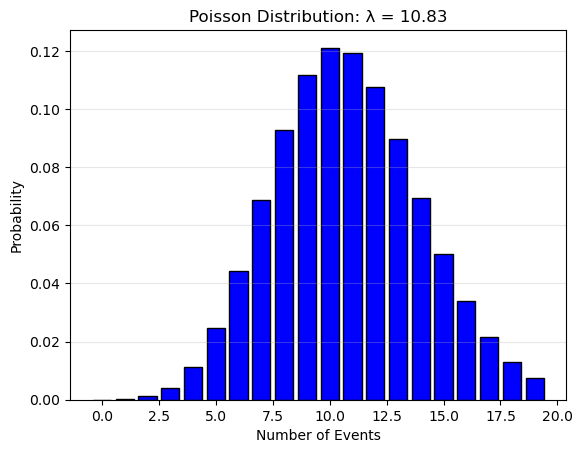

In [33]:
lambda_value = 10.83  # Average number of events in the interval
k = np.arange(0, 20)  # Number of possible events (0 to 20)

# Poisson probability mass function (pmf)
poisson_pmf = poisson.pmf(k, lambda_value)

# Plot the Poisson distribution
plt.bar(k, poisson_pmf, color='blue', edgecolor='black')

plt.title('Poisson Distribution: λ = 10.83')
plt.xlabel('Number of Events')
plt.ylabel('Probability')
plt.grid(axis='y', alpha=0.3)
plt.show()


### Normal distribution

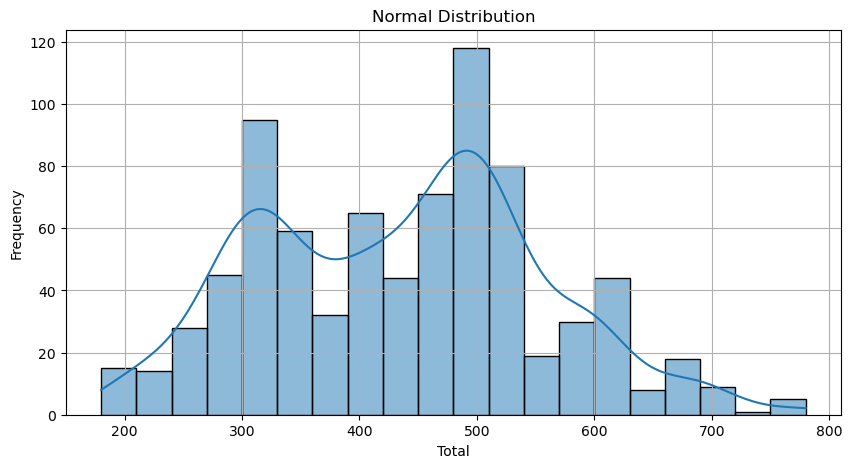

In [34]:
# Plot normal distribution using Total

plt.figure(figsize=(10, 5))
sns.histplot(df['Total'], bins=20, kde=True)
plt.title('Normal Distribution')
plt.xlabel('Total')
plt.ylabel('Frequency')
plt.grid()
plt.show()

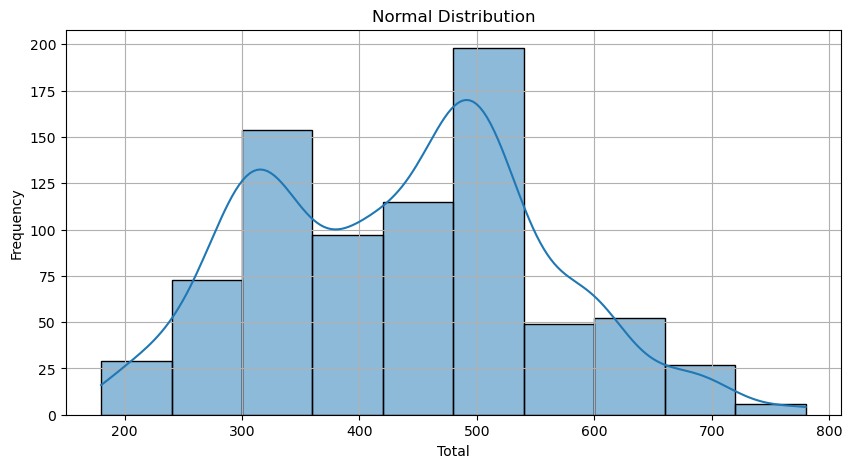

In [42]:
plt.figure(figsize=(10, 5))
sns.histplot(df['Total'], bins=10, kde=True)
plt.title('Normal Distribution')
plt.xlabel('Total')
plt.ylabel('Frequency')
plt.grid()
plt.show()